Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 21ms/step - accuracy: 0.8666 - loss: 0.4218 - val_accuracy: 0.9860 - val_loss: 0.0601
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9831 - loss: 0.0554 - val_accuracy: 0.9897 - val_loss: 0.0398
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9882 - loss: 0.0359 - val_accuracy: 0.9877 - val_loss: 0.0410
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9913 - loss: 0.0276 - val_accuracy: 0.9905 - val_loss: 0.0347
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.9935 - loss: 0.0208 - val_accuracy: 0.9902 - val_loss: 0.0375
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.9946 - loss: 0.0178 - val_accuracy: 0.9892 - val_loss: 0.0440
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9955 - loss: 0.0125 - val_accuracy: 0.9907 - val_loss: 0.0345
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9976 - loss: 0.0088 - 

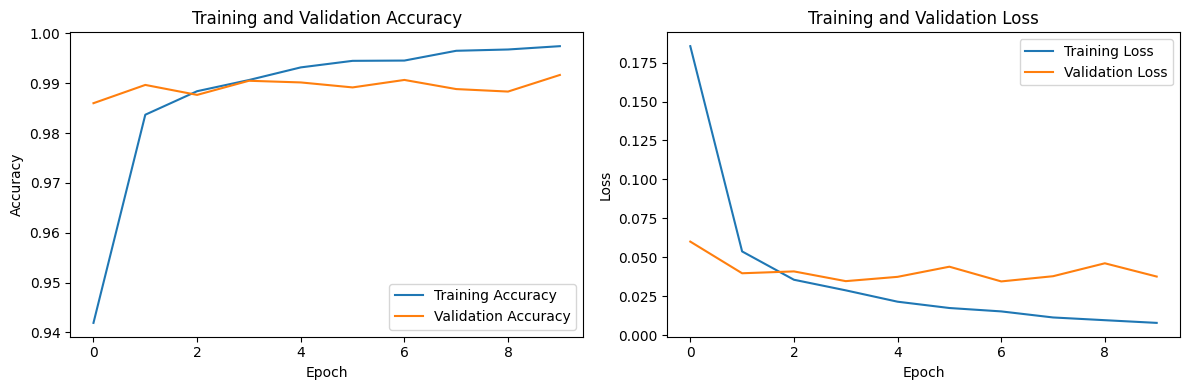

In [3]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

train_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_test.csv")

y_train = train_data["label"].values
y_test = test_data["label"].values

x_train = train_data.drop("label", axis=1).values
x_test = test_data.drop("label", axis=1).values

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Loss: ", loss * 100)
print("Accuracy: ", accuracy * 100)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()